In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("/content/mohali_weather_2016_2025.csv", skiprows=2)

In [3]:
df.head()

,time,weather_code (wmo code),temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),wind_speed_10m_max (km/h),relative_humidity_2m_mean (%)
0,2016-01-01,3,13.8,21.4,9.5,0.0,8.0,62
1,2016-01-02,3,13.3,21.5,7.5,0.0,12.2,65
2,2016-01-03,2,13.4,22.0,8.1,0.0,16.7,69
3,2016-01-04,3,13.6,19.1,8.5,0.0,6.4,74
4,2016-01-05,3,16.3,24.0,11.7,0.0,9.8,66


In [4]:
df.shape

(3653, 8)

In [5]:
df.dtypes

,0
time,object
weather_code (wmo code),int64
temperature_2m_mean (°C),float64
temperature_2m_max (°C),float64
temperature_2m_min (°C),float64
precipitation_sum (mm),float64
wind_speed_10m_max (km/h),float64
relative_humidity_2m_mean (%),int64


In [6]:
df["time"] = pd.to_datetime(df["time"])

In [7]:
df.dtypes

,0
time,datetime64[ns]
weather_code (wmo code),int64
temperature_2m_mean (°C),float64
temperature_2m_max (°C),float64
temperature_2m_min (°C),float64
precipitation_sum (mm),float64
wind_speed_10m_max (km/h),float64
relative_humidity_2m_mean (%),int64


In [8]:
df.isna().sum()

,0
time,0
weather_code (wmo code),0
temperature_2m_mean (°C),0
temperature_2m_max (°C),0
temperature_2m_min (°C),0
precipitation_sum (mm),0
wind_speed_10m_max (km/h),0
relative_humidity_2m_mean (%),0


In [9]:
df["time"].duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,time,weather_code (wmo code),temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),wind_speed_10m_max (km/h),relative_humidity_2m_mean (%)
count,3653,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000
mean,2020-12-31 00:00:00,24.205311,24.496469,30.378128,19.731618,2.017438,13.465508,64.858472
min,2016-01-01 00:00:00,0.000000,8.600000,11.900000,4.400000,0.000000,4.500000,18.000000
25%,2018-07-02 00:00:00,1.000000,18.000000,25.300000,13.000000,0.000000,9.800000,53.000000
50%,2020-12-31 00:00:00,3.000000,26.800000,31.900000,21.000000,0.000000,12.800000,69.000000
75%,2023-07-02 00:00:00,51.000000,30.200000,35.000000,26.500000,1.000000,16.300000,78.000000
max,2025-12-31 00:00:00,65.000000,39.100000,45.800000,32.800000,162.500000,43.600000,96.000000
std,NaN,26.649114,7.089293,6.853298,7.168158,7.685054,4.625390,16.782856


In [11]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
time,3653,2020-12-31 00:00:00,2016-01-01 00:00:00,2018-07-02 00:00:00,2020-12-31 00:00:00,2023-07-02 00:00:00,2025-12-31 00:00:00,NaN
weather_code (wmo code),3653.0,24.205311,0.0,1.0,3.0,51.0,65.0,26.649114
temperature_2m_mean (°C),3653.0,24.496469,8.6,18.0,26.8,30.2,39.1,7.089293
temperature_2m_max (°C),3653.0,30.378128,11.9,25.3,31.9,35.0,45.8,6.853298
temperature_2m_min (°C),3653.0,19.731618,4.4,13.0,21.0,26.5,32.8,7.168158
precipitation_sum (mm),3653.0,2.017438,0.0,0.0,0.0,1.0,162.5,7.685054
wind_speed_10m_max (km/h),3653.0,13.465508,4.5,9.8,12.8,16.3,43.6,4.62539
relative_humidity_2m_mean (%),3653.0,64.858472,18.0,53.0,69.0,78.0,96.0,16.782856


In [12]:
expected_days = pd.date_range(start="2016-01-01", end="2025-12-31")

len(expected_days), len(df)

(3653, 3653)

In [13]:
df["time"].diff().value_counts()

,count
time,
1 days,3652


In [14]:
df = df.rename(columns={
    "time": "date",
    "weather_code (wmo code)": "weather_code",
    "temperature_2m_mean (°C)": "temp_mean",
    "temperature_2m_max (°C)": "temp_max",
    "temperature_2m_min (°C)": "temp_min",
    "precipitation_sum (mm)": "rainfall",
    "wind_speed_10m_max (km/h)": "wind_speed",
    "relative_humidity_2m_mean (%)": "humidity"
})

In [15]:
df.head()

,date,weather_code,temp_mean,temp_max,temp_min,rainfall,wind_speed,humidity
0,2016-01-01,3,13.8,21.4,9.5,0.0,8.0,62
1,2016-01-02,3,13.3,21.5,7.5,0.0,12.2,65
2,2016-01-03,2,13.4,22.0,8.1,0.0,16.7,69
3,2016-01-04,3,13.6,19.1,8.5,0.0,6.4,74
4,2016-01-05,3,16.3,24.0,11.7,0.0,9.8,66


In [16]:
df = df.sort_values("date").reset_index(drop=True)

In [17]:
df[["date", "temp_mean", "rainfall"]].head()

,date,temp_mean,rainfall
0,2016-01-01,13.8,0.0
1,2016-01-02,13.3,0.0
2,2016-01-03,13.4,0.0
3,2016-01-04,13.6,0.0
4,2016-01-05,16.3,0.0


In [18]:
df[["date", "temp_mean", "temp_max", "temp_min"]].head()

,date,temp_mean,temp_max,temp_min
0,2016-01-01,13.8,21.4,9.5
1,2016-01-02,13.3,21.5,7.5
2,2016-01-03,13.4,22.0,8.1
3,2016-01-04,13.6,19.1,8.5
4,2016-01-05,16.3,24.0,11.7


Creating a month column

In [20]:
df["month"] = df["date"].dt.month

In [21]:
df[["date", "month"]].head()

,date,month
0,2016-01-01,1
1,2016-01-02,1
2,2016-01-03,1
3,2016-01-04,1
4,2016-01-05,1


Calculating avg temp by month

In [23]:
monthly_temp = df.groupby("month")["temp_mean"].mean()
monthly_temp

,temp_mean
month,
1,13.033871
2,17.124028
3,22.370968
4,28.670667
5,31.659355
6,32.639667
7,30.416774
8,29.640000
9,28.957000


Visualising the seasonal pattern

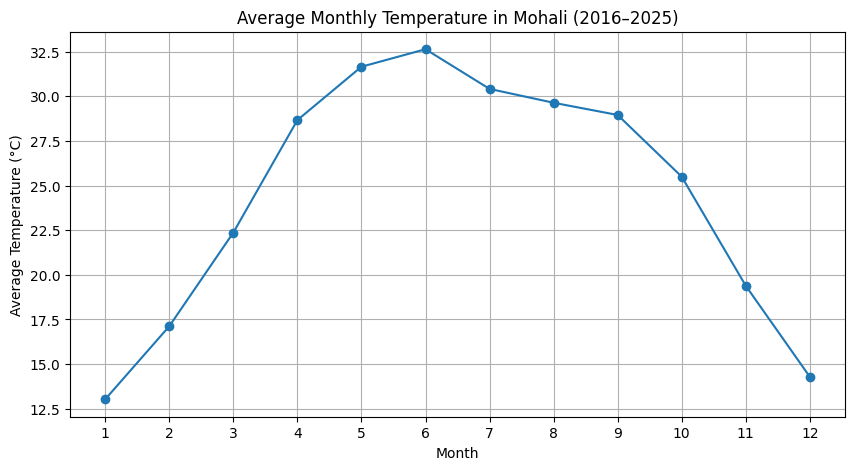

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(monthly_temp.index, monthly_temp.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Monthly Temperature in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

**Observation:** The average temperature increases from January to June, reaching the highest value in June (about 32.4°C). It then decreases until December. This shows a clear seasonal pattern in Mohali.

Looking at yearly temperature variation

In [26]:
df["year"] = df["date"].dt.year
yearly_temp = df.groupby("year")["temp_mean"].mean()
yearly_temp

,temp_mean
year,
2016,25.260929
2017,24.959452
2018,24.420822
2019,24.100274
2020,24.113934
2021,24.334795
2022,24.966575
2023,24.010685
2024,24.476503


Visualizing the yearly averages

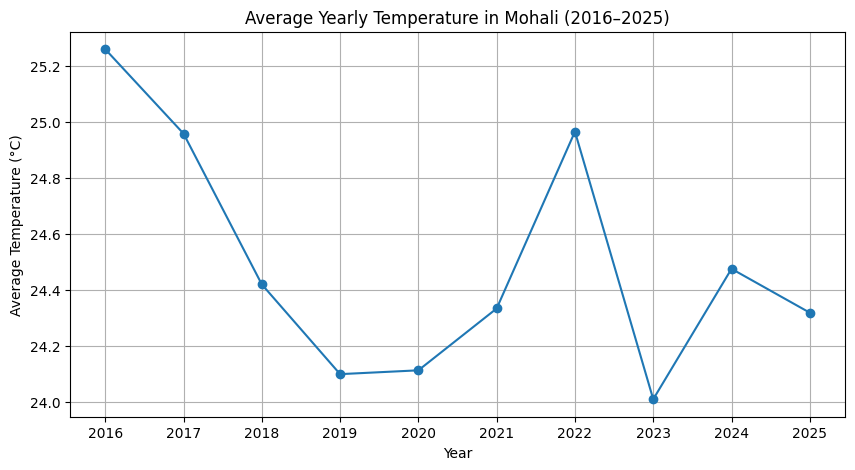

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(yearly_temp.index, yearly_temp.values, marker="o")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Yearly Temperature in Mohali (2016–2025)")
plt.xticks(yearly_temp.index)
plt.grid(True)
plt.show()

**Observation:** The yearly average temperature varies slightly from year to year. It decreases from 2016 to 2019 and then shows fluctuations, with a noticeable increase in 2022 followed by a decrease in 2023.

Looking at temperature ranges

In [28]:
monthly_max = df.groupby("month")["temp_max"].mean()
monthly_min = df.groupby("month")["temp_min"].mean()
monthly_max, monthly_min

(month
 1     18.625161
 2     23.796466
 3     29.288710
 4     36.131667
 5     38.239355
 6     37.839667
 7     33.650968
 8     32.849355
 9     33.105333
 10    32.429032
 11    27.008000
 12    21.406129
 Name: temp_max, dtype: float64,
 month
 1      9.208065
 2     12.045583
 3     16.477742
 4     21.644667
 5     25.261613
 6     27.551333
 7     27.642903
 8     27.067742
 9     25.619667
 10    20.050000
 11    14.126667
 12     9.737097
 Name: temp_min, dtype: float64)

Comparing monthly maximum and minimum temperatures

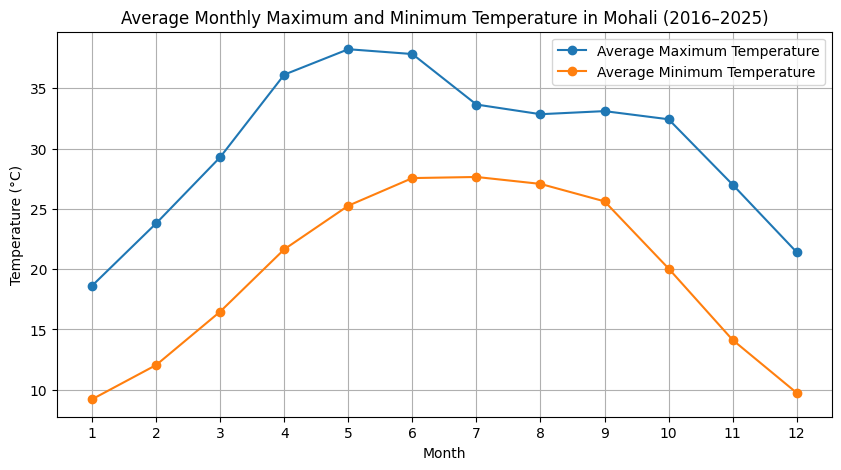

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_max.index, monthly_max.values, marker="o", label="Average Maximum Temperature")
plt.plot(monthly_min.index, monthly_min.values, marker="o", label="Average Minimum Temperature")

plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.title("Average Monthly Maximum and Minimum Temperature in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.show()

**Observation:** Average maximum and minimum temperatures both show a clear seasonal pattern. They increase toward the summer months and decrease toward winter. The highest temperatures occur around May–June, while the lowest values occur during the winter months.

Seasonal temperature analysis

In [31]:
season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

df["season"] = df["month"].map(season_map)
df[["date", "month", "season"]].head(15)

,date,month,season
0,2016-01-01,1,Winter
1,2016-01-02,1,Winter
2,2016-01-03,1,Winter
3,2016-01-04,1,Winter
4,2016-01-05,1,Winter
5,2016-01-06,1,Winter
6,2016-01-07,1,Winter
7,2016-01-08,1,Winter
8,2016-01-09,1,Winter
9,2016-01-10,1,Winter


Calculating average temperature for each season

In [32]:
seasonal_temp = df.groupby("season")["temp_mean"].mean()
seasonal_temp

,temp_mean
season,
Autumn,24.625165
Spring,27.555000
Summer,30.879891
Winter,14.747065


**Observation:** Summer has the highest average temperature (about 30.9°C), while winter has the lowest (about 14.7°C). Spring and autumn have intermediate temperatures, showing a clear seasonal pattern.

Visualizing the seasonal temperatures

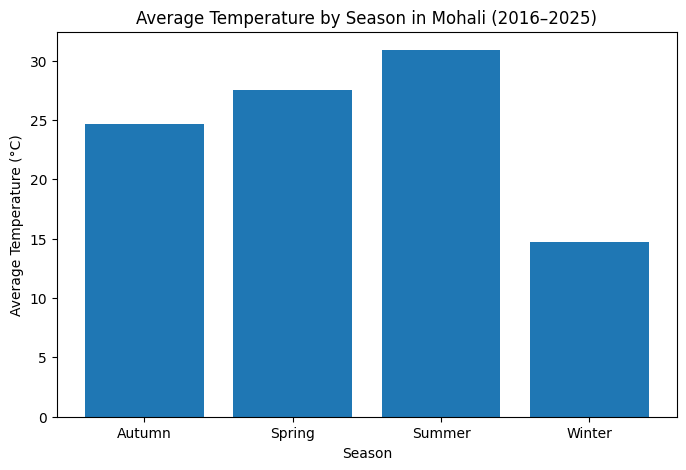

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(seasonal_temp.index, seasonal_temp.values)

plt.xlabel("Season")
plt.ylabel("Average Temperature (°C)")
plt.title("Average Temperature by Season in Mohali (2016–2025)")
plt.show()

Doing rainfall analysis

In [34]:
df["rainfall"].describe()

,rainfall
count,3653.000000
mean,2.017438
std,7.685054
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,162.500000


In [35]:
rainy_days = (df["rainfall"] > 0).sum()
rainy_days

np.int64(1548)

In [36]:
rainy_percentage = (rainy_days / len(df)) * 100
rainy_percentage

np.float64(42.37612920886942)

**Observation**: Out of 3,653 days, 1,548 days had measurable rainfall. This means about 42.4% of the days were rainy, while the remaining days had no measurable rainfall.

Rainfall distribution

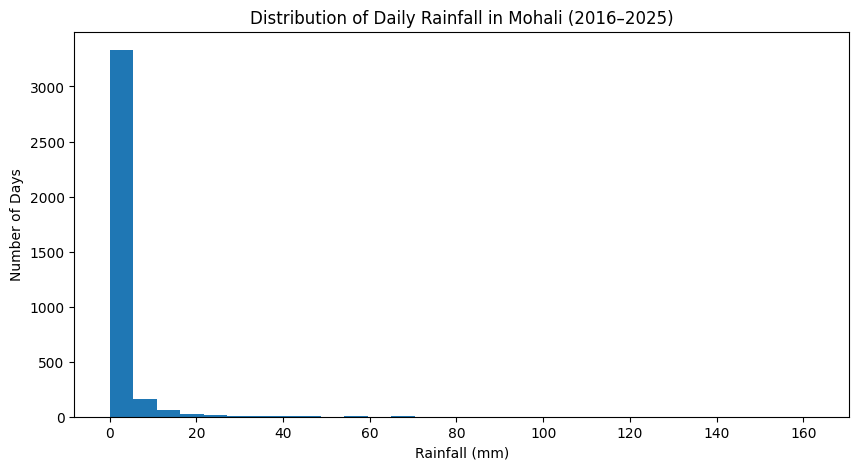

In [37]:
plt.figure(figsize=(10, 5))

plt.hist(df["rainfall"], bins=30)

plt.xlabel("Rainfall (mm)")
plt.ylabel("Number of Days")
plt.title("Distribution of Daily Rainfall in Mohali (2016–2025)")
plt.show()

**Observation:** Daily rainfall is concentrated at the lower rainfall values, while higher rainfall amounts occur much less frequently. The distribution has a long tail toward heavier rainfall events.

Monthly rainfall pattern

In [38]:
monthly_rainfall = df.groupby("month")["rainfall"].mean()
monthly_rainfall

,rainfall
month,
1,1.644516
2,1.099293
3,1.098710
4,0.610333
5,1.085806
6,1.730000
7,6.510000
8,5.670968
9,3.564333


**Observation:** Average daily rainfall is highest during July and August and remains relatively high in September. Rainfall is much lower during the other months, especially October and November.

Visualizing monthly rainfall

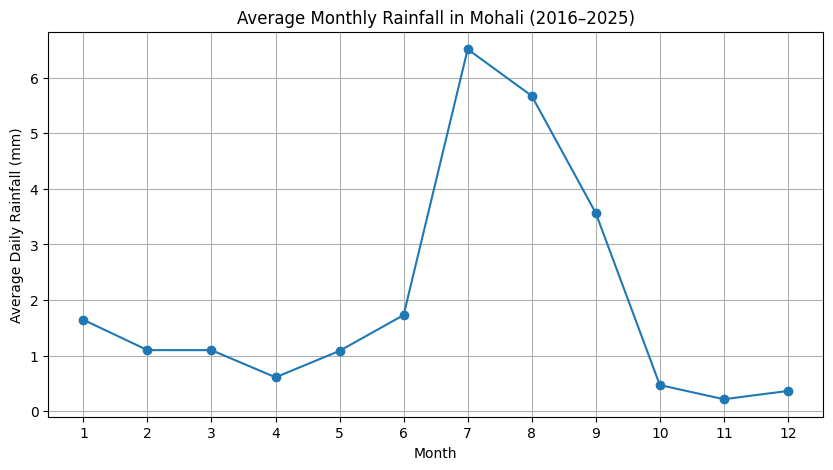

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_rainfall.index, monthly_rainfall.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Average Daily Rainfall (mm)")
plt.title("Average Monthly Rainfall in Mohali (2016–2025)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

**Observation:** Average daily rainfall is highest in July and August, with July showing the highest value. Rainfall decreases after September and remains low during October to December.

Final rainfall analysis

In [40]:
seasonal_rainfall = df.groupby("season")["rainfall"].mean()
seasonal_rainfall

,rainfall
season,
Autumn,1.406813
Spring,0.935109
Summer,4.668587
Winter,1.034441


**Observation:** Summer has the highest average daily rainfall (about 4.7 mm), while spring has the lowest (about 0.9 mm). Rainfall is much higher in summer than in the other seasons.